In [125]:
# @title
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import loguniform

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

In [ ]:
# @title
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
elo = pd.read_csv("elo_ratings_wc2026.csv")

print("Historical training data shape:", train.shape)
print("2026 prediction data shape:", test.shape)

display(train.head())
train.info()

In [ ]:
# @title
print("Missing values in training data:")
display(train.isna().sum())

print("Target balance:")
display(train["quarter_finalist"].value_counts())

print("Tournament outcome totals:")
display(train[["winner", "finalist", "semi_finalist", "quarter_finalist"]].sum())

In [128]:
# @title
features = [
    "is_host",
    "goals_scored_last_4y",
    "wins_last_4y",
    "losses_last_4y",
    "draws_last_4y",
    "world_cup_titles_before",
    "squad_total_market_value_eur",
    "fifa_rank_pre_tournament",
    "fifa_points_pre_tournament",
    "squad_avg_age",
    "world_cup_participations_before",
    "groups_passed_before",
    "round16_before",
    "quarterfinals_before",
    "semifinals_before",
    "finals_before"
]

X = train[features]
y = train["quarter_finalist"]

In [ ]:
# @title
plt.figure(figsize=(6, 4))
train["quarter_finalist"].value_counts().plot(kind="bar")
plt.title("Distribution of Quarterfinalists")
plt.xlabel("Quarterfinalist")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(7, 5))
sns.boxplot(
    x="quarter_finalist",
    y="squad_total_market_value_eur",
    data=train
)
plt.title("Squad Market Value by Quarterfinalist Status")
plt.xlabel("Quarterfinalist")
plt.ylabel("Squad Market Value (EUR)")
plt.show()

plt.figure(figsize=(7, 5))
sns.boxplot(
    x="quarter_finalist",
    y="fifa_rank_pre_tournament",
    data=train
)
plt.title("FIFA Rank by Quarterfinalist Status")
plt.xlabel("Quarterfinalist")
plt.ylabel("FIFA Rank Before Tournament")
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(
    train[features + ["quarter_finalist"]].corr(),
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap of Team Features")
plt.show()

In [ ]:
# @title
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training class balance:")
display(y_train.value_counts(normalize=True))

print("Testing class balance:")
display(y_test.value_counts(normalize=True))

In [ ]:
# @title
tree_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(random_state=42))
])

tree_pipeline.fit(X_train, y_train)

tree_pred = tree_pipeline.predict(X_test)

print("Decision Tree Accuracy:", accuracy_score(y_test, tree_pred))
print("Decision Tree Confusion Matrix:")
print(confusion_matrix(y_test, tree_pred))
print("Decision Tree Classification Report:")
print(classification_report(y_test, tree_pred))

tree_model = tree_pipeline.named_steps["model"]

importance = pd.DataFrame({
    "Feature": features,
    "Importance": tree_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance)

plt.figure(figsize=(10, 6))
plt.barh(importance["Feature"], importance["Importance"])
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("Decision Tree Feature Importance")
plt.show()

In [ ]:
# @title
svm_baseline_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", SVC(probability=True, random_state=42))
])

svm_baseline_pipeline.fit(X_train, y_train)

svm_baseline_pred = svm_baseline_pipeline.predict(X_test)
svm_baseline_prob = svm_baseline_pipeline.predict_proba(X_test)[:, 1]

print("Baseline SVM Accuracy:", accuracy_score(y_test, svm_baseline_pred))
print("Baseline SVM ROC-AUC:", roc_auc_score(y_test, svm_baseline_prob))
print("Baseline SVM Confusion Matrix:")
print(confusion_matrix(y_test, svm_baseline_pred))
print("Baseline SVM Classification Report:")
print(classification_report(y_test, svm_baseline_pred))

In [ ]:
# @title
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

svm_tuned_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", SVC(probability=True, random_state=42))
])

svm_params = {
    "model__C": loguniform(0.1, 100),
    "model__gamma": ["scale"],
    "model__kernel": ["rbf"]
}

svm_search = RandomizedSearchCV(
    estimator=svm_tuned_pipeline,
    param_distributions=svm_params,
    n_iter=10,
    cv=cv,
    scoring="roc_auc",
    random_state=42,
    n_jobs=-1
)

svm_search.fit(X_train, y_train)

print("Best Tuned SVM Parameters:")
print(svm_search.best_params_)

print("Best CV ROC-AUC:")
print(svm_search.best_score_)

svm_tuned_best = svm_search.best_estimator_

svm_tuned_prob = svm_tuned_best.predict_proba(X_test)[:, 1]

In [ ]:
# @title
threshold_results = []

for threshold in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    pred_threshold = (svm_tuned_prob >= threshold).astype(int)

    report = classification_report(
        y_test,
        pred_threshold,
        output_dict=True,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, pred_threshold),
        "Precision_Quarterfinalist": report["1"]["precision"],
        "Recall_Quarterfinalist": report["1"]["recall"],
        "F1_Quarterfinalist": report["1"]["f1-score"]
    })

threshold_table = pd.DataFrame(threshold_results)

display(threshold_table)

final_threshold = 0.20

svm_final_pred = (svm_tuned_prob >= final_threshold).astype(int)

print("Final Tuned SVM Accuracy:", accuracy_score(y_test, svm_final_pred))
print("Final Tuned SVM ROC-AUC:", roc_auc_score(y_test, svm_tuned_prob))
print("Final Tuned SVM Confusion Matrix:")
print(confusion_matrix(y_test, svm_final_pred))
print("Final Tuned SVM Classification Report:")
print(classification_report(y_test, svm_final_pred))

In [ ]:
# @title
model_comparison = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Baseline SVM",
        "Tuned SVM with 0.20 Threshold"
    ],
    "Accuracy": [
        accuracy_score(y_test, tree_pred),
        accuracy_score(y_test, svm_baseline_pred),
        accuracy_score(y_test, svm_final_pred)
    ],
    "ROC_AUC": [
        np.nan,
        roc_auc_score(y_test, svm_baseline_prob),
        roc_auc_score(y_test, svm_tuned_prob)
    ],
    "Recall_Quarterfinalist": [
        classification_report(y_test, tree_pred, output_dict=True)["1"]["recall"],
        classification_report(y_test, svm_baseline_pred, output_dict=True)["1"]["recall"],
        classification_report(y_test, svm_final_pred, output_dict=True)["1"]["recall"]
    ],
    "F1_Quarterfinalist": [
        classification_report(y_test, tree_pred, output_dict=True)["1"]["f1-score"],
        classification_report(y_test, svm_baseline_pred, output_dict=True)["1"]["f1-score"],
        classification_report(y_test, svm_final_pred, output_dict=True)["1"]["f1-score"]
    ]
})

display(model_comparison)

In [ ]:
# @title
X_2026 = test[features]

test["quarterfinal_probability"] = svm_tuned_best.predict_proba(X_2026)[:, 1]
test["quarterfinal_prediction_threshold_020"] = (
    test["quarterfinal_probability"] >= final_threshold
).astype(int)

predictions_2026 = test[
    ["team", "quarterfinal_probability", "quarterfinal_prediction_threshold_020"]
].sort_values(
    "quarterfinal_probability",
    ascending=False
)

display(predictions_2026.head(20))

In [ ]:
# @title
unsup_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_scaled = unsup_pipeline.fit_transform(X)

pca = PCA(n_components=2)
pc = pca.fit_transform(X_scaled)

print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("Total Explained Variance:")
print(pca.explained_variance_ratio_.sum())

loadings = pd.DataFrame(
    pca.components_.T,
    columns=["PC1", "PC2"],
    index=features
)

display(loadings.sort_values("PC1", ascending=False))

plt.figure(figsize=(8, 6))
plt.scatter(pc[:, 0], pc[:, 1], c=y)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of World Cup Team Features")
plt.colorbar(label="Quarterfinalist")
plt.show()

In [ ]:
# @title
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(pc)

train["cluster"] = clusters

plt.figure(figsize=(8, 6))
plt.scatter(pc[:, 0], pc[:, 1], c=clusters)
plt.xlabel("PC1: Historical World Cup Strength")
plt.ylabel("PC2: Recent Form")
plt.title("K-Means Clustering of World Cup Teams")
plt.show()

cluster_summary = train.groupby("cluster")[features].mean()
display(cluster_summary)

for c in sorted(train["cluster"].unique()):
    print("Cluster", c)
    display(train[train["cluster"] == c][["version", "team"]].head(15))

In [ ]:
# @title
comparison_table = (
    elo_comparison[
        ["team", "quarterfinal_probability", "rank"]
    ]
    .rename(columns={
        "team": "Team",
        "quarterfinal_probability": "SVM Probability (%)",
        "rank": "Elo Rank"
    })
)

comparison_table["SVM Probability (%)"] = (
    comparison_table["SVM Probability (%)"] * 100
).round(1)

comparison_table = comparison_table.sort_values(
    "SVM Probability (%)",
    ascending=False
).head(10)

display(comparison_table)

In [ ]:
# @title
predictions_2026.to_csv("worldcup_2026_predictions.csv", index=False)
model_comparison.to_csv("model_comparison.csv", index=False)
threshold_table.to_csv("threshold_analysis.csv", index=False)
cluster_summary.to_csv("cluster_summary.csv")
importance.to_csv("decision_tree_feature_importance.csv", index=False)

print("Saved output tables.")

# Predicting FIFA World Cup 2026 Quarterfinalists Using Machine Learning

Name: Haofan Liao  
Email: haofan@ucsb.edu

## Abstract
This project applies supervised and unsupervised learning methods to FIFA World Cup data. The goal is to identify factors associated with reaching the quarterfinals and to predict possible 2026 quarterfinalists.

## 1. Introduction

The FIFA World Cup is the most prestigious international football tournament and attracts global attention from fans, media organizations, and sports analysts. As the 2026 FIFA World Cup approaches, there is increasing interest in understanding which factors contribute to tournament success and how data-driven methods can be used to generate predictions. While predicting the eventual champion is highly challenging due to the uncertainty of knockout-stage football, predicting whether a team reaches the quarterfinals provides a more stable and informative measure of tournament success. Therefore, this project focuses on quarterfinal qualification as the primary outcome of interest.

To investigate this problem, the project applies both supervised and unsupervised learning techniques to historical FIFA World Cup data. Supervised learning methods are used to classify whether a team reaches the quarterfinal stage, while unsupervised learning methods are used to identify patterns and similarities among teams. In addition, the analysis explores the relative importance of factors such as recent performance, FIFA rankings, squad market value, and historical World Cup experience in determining tournament success.

To support this analysis, the dataset combines both historical and contemporary measures of team quality. Historical indicators such as previous World Cup appearances and titles capture long-term competitive strength and tournament experience, while recent performance measures such as goals scored, wins, FIFA rankings, and squad market value reflect current form. By integrating these complementary dimensions, the dataset provides a comprehensive view of team strength prior to the 2026 FIFA World Cup and serves as a suitable foundation for predictive modeling and exploratory analysis.

## 2. Data

The primary data source for this project is the FIFA World Cup Dataset obtained from Kaggle. It contains team-level information from World Cup tournaments between 2002 and 2022, together with a separate dataset representing the 48 teams qualified for the 2026 FIFA World Cup. Each observation corresponds to a national team participating in a specific tournament. The historical dataset contains 192 observations and 25 variables, while the 2026 dataset is used for out-of-sample prediction.

The data were selected because they capture both recent performance and long-term competitive strength. Recent indicators include goals scored, wins, losses, draws, FIFA rankings, and FIFA points, while historical measures include previous World Cup appearances, quarterfinals, semifinals, finals, and titles. Additional variables such as squad market value and average squad age provide information on team quality and experience.

To further evaluate the model’s predictions, a supplementary Elo rating dataset was also obtained from Kaggle. Although Elo ratings were not used as input features during model training, they serve as an external benchmark against which the model’s predictions can be compared.

Overall, the data provide a comprehensive representation of team performance by combining current form, historical success, and squad characteristics within a structured tabular format. This makes the dataset well suited for both predictive modeling and exploratory analysis, while the dedicated 2026 dataset allows the trained models to be applied to a future tournament.

### Table 1. Dataset Summary

In [141]:
# @title
print("Training observations:", train.shape[0])
print("Prediction observations:", test.shape[0])
print("Number of variables:", train.shape[1])

Training observations: 192
Prediction observations: 48
Number of variables: 25


The training dataset contains 192 historical team observations and 25 variables capturing recent performance, historical success, and squad characteristics. The target variable, quarter_finalist, is a binary indicator of quarterfinal qualification.

## 3. Methodology

### 3.1 Data Preprocessing

To address missing values in squad market value, median imputation was applied. Median imputation is appropriate for skewed numerical variables because it is less sensitive to extreme observations than mean imputation. The target variable for this study was quarter_finalist, a binary indicator of whether a team reached the quarterfinal stage of the tournament. The data were divided into training (80%) and testing (20%) sets using stratified sampling to preserve the proportion of quarterfinalist and non-quarterfinalist teams. Because Support Vector Machines are sensitive to feature scale, numerical predictors were standardized prior to model fitting.

### 3.2 Supervised Learning

Two supervised learning methods were applied: a Decision Tree classifier and a Support Vector Machine (SVM). The Decision Tree was included because of its interpretability and ability to identify the variables most strongly associated with quarterfinal qualification. The SVM was selected as the primary predictive model because it can capture complex nonlinear relationships among predictors and often performs well on structured tabular datasets.

To improve model performance, hyperparameter tuning was conducted for the SVM using Randomized Search with stratified five-fold cross-validation. The tuning process considered alternative values of the regularization parameter (C) and kernel specifications. Model performance was evaluated using accuracy, precision, recall, F1-score, ROC-AUC, and confusion matrices. Because identifying successful teams was of particular interest, probability threshold analysis was also performed to examine the trade-off between recall and overall classification accuracy.

### 3.3 Unsupervised Learning

In addition to predictive modeling, unsupervised learning techniques were used to explore the underlying structure of the data. Principal Component Analysis (PCA) was applied to reduce dimensionality and identify the dominant sources of variation among teams. K-Means clustering was then performed on the principal components to group teams with similar characteristics. These methods complement the supervised analysis by revealing patterns and relationships that are not directly tied to quarterfinal qualification.

## 4. Results

### 4.1 Exploratory Data Analysis

#### Figure 1. Distribution of Quarterfinalists



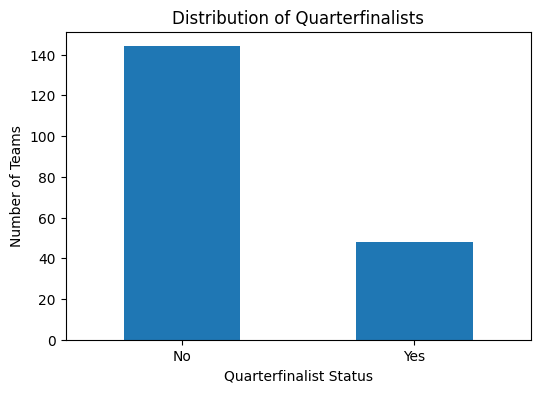

In [165]:
# @title
plt.figure(figsize=(6, 4))
train["quarter_finalist"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribution of Quarterfinalists")
plt.xlabel("Quarterfinalist Status")
plt.ylabel("Number of Teams")
plt.xticks([0, 1], ["No", "Yes"], rotation=0)
plt.show()


Figure 1 shows the distribution of the target variable. Most teams in the dataset did not reach the quarterfinal stage, resulting in a moderately imbalanced classification problem. This observation motivated the use of stratified sampling during data splitting and cross-validation to preserve class proportions across training and testing datasets. Having established the structure of the target variable, the next step is to examine whether differences in team characteristics are associated with quarterfinal qualification.

#### Figure 2. Squad Market Value by Quarterfinalist Status



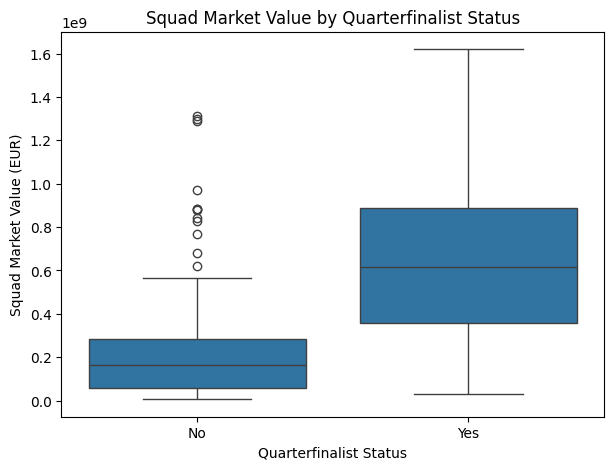

In [143]:
# @title
plt.figure(figsize=(7, 5))
sns.boxplot(
    x="quarter_finalist",
    y="squad_total_market_value_eur",
    data=train
)
plt.title("Squad Market Value by Quarterfinalist Status")
plt.xlabel("Quarterfinalist Status")
plt.ylabel("Squad Market Value (EUR)")
plt.xticks([0, 1], ["No", "Yes"])
plt.show()

Figure 2 compares squad market values between quarterfinalist and non-quarterfinalist teams. The median market value of quarterfinalist teams is substantially higher than that of non-quarterfinalist teams, suggesting that stronger and more valuable squads are associated with tournament success. Although several non-quarterfinalist teams also possessed high market values, the overall distribution indicates that squad quality is an important factor in reaching the later stages of the World Cup. However, squad value alone may not fully explain tournament outcomes. International football rankings provide another widely used measure of team strength and are examined next.
#### Figure 3. FIFA Rank by Quarterfinalist Status



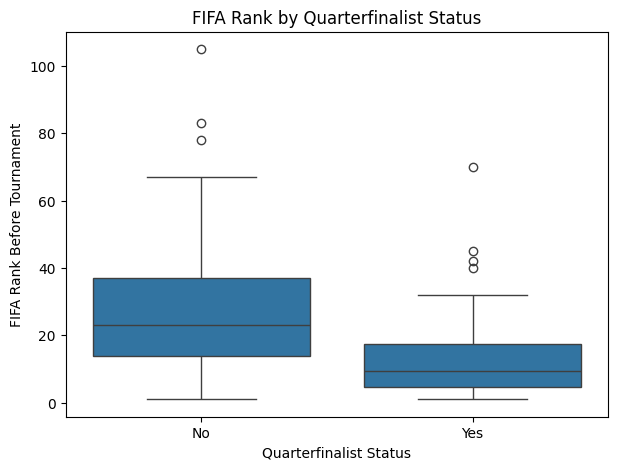

In [144]:
# @title
plt.figure(figsize=(7, 5))
sns.boxplot(
    x="quarter_finalist",
    y="fifa_rank_pre_tournament",
    data=train
)
plt.title("FIFA Rank by Quarterfinalist Status")
plt.xlabel("Quarterfinalist Status")
plt.ylabel("FIFA Rank Before Tournament")
plt.xticks([0, 1], ["No", "Yes"])
plt.show()


Figure 3 compares FIFA rankings between quarterfinalist and non-quarterfinalist teams. Quarterfinalist teams generally entered the tournament with lower ranking values, indicating stronger FIFA rankings. The distribution suggests that internationally recognized team strength is associated with a greater likelihood of advancing to the quarterfinal stage. However, several lower-ranked teams also reached the quarterfinals, highlighting the uncertainty inherent in tournament competition. Taken together, Figures 2 and 3 suggest that both squad quality and competitive performance may influence success. To better understand how these factors interact, a correlation analysis was conducted.
#### Figure 4. Correlation Heatmap

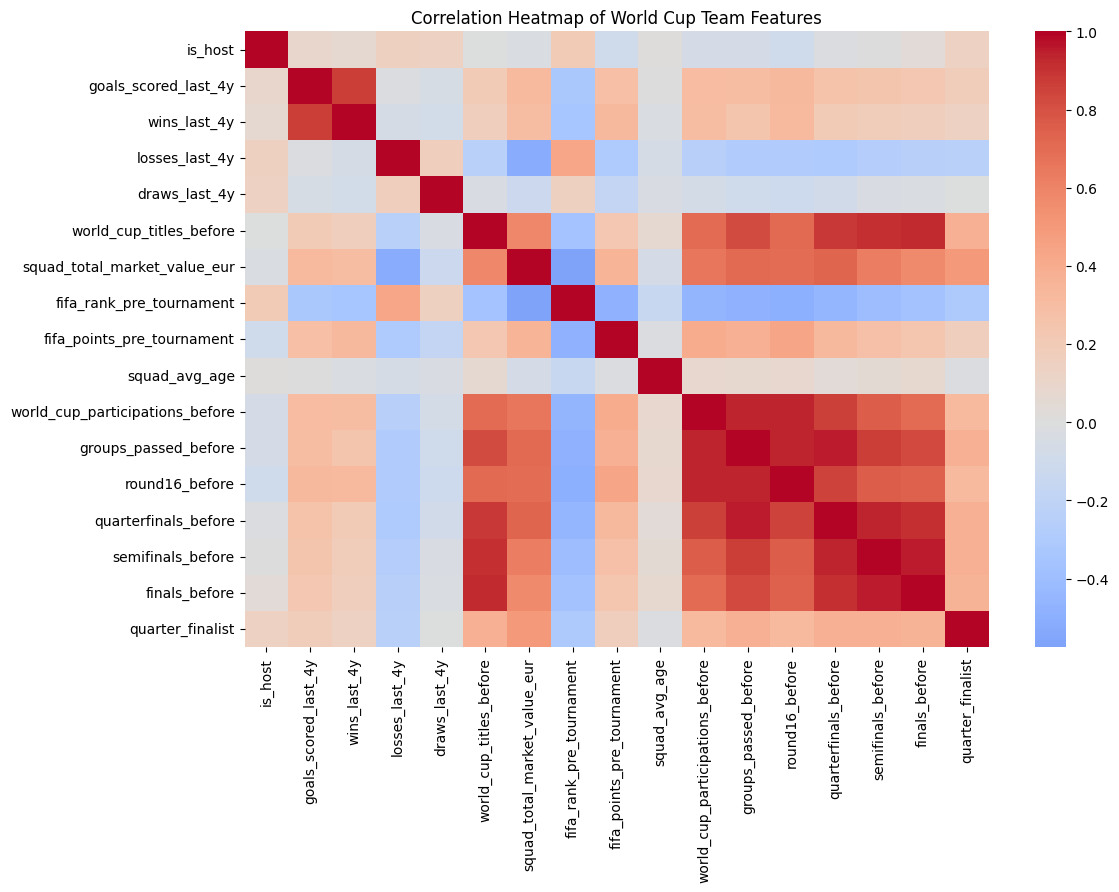

In [145]:
# @title
plt.figure(figsize=(12, 8))
sns.heatmap(
    train[features + ["quarter_finalist"]].corr(),
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap of World Cup Team Features")
plt.show()

Figure 4 presents the correlation structure among the predictor variables and the target variable. Historical World Cup success variables, including previous quarterfinal, semifinal, and final appearances, exhibit strong positive relationships with one another and with quarterfinal qualification. Recent performance measures such as wins, goals scored, and FIFA points also show positive associations with success. In contrast, FIFA ranking displays a negative relationship because lower ranking values correspond to stronger teams. These findings suggest that both historical experience and recent form contribute to tournament success, providing justification for the supervised learning models developed in the next section.
### 4.2 Supervised Learning Results

#### Table 3. Model Performance Comparison

In [146]:
# @title
display(model_comparison)

,Model,Accuracy,ROC_AUC,Recall_Quarterfinalist,F1_Quarterfinalist
0,Decision Tree,0.794872,NaN,0.7,0.636364
1,Baseline SVM,0.846154,0.696552,0.4,0.571429
2,Tuned SVM with 0.20 Threshold,0.846154,0.689655,0.6,0.666667


Table 3 compares the predictive performance of the supervised learning models. The baseline Support Vector Machine achieved the highest classification accuracy, while the Decision Tree achieved the highest recall among the initial models. After threshold optimization, the tuned SVM improved recall from 40% to 60% while maintaining an overall accuracy of 84.6%. Because the primary objective of this project is to identify future quarterfinalist teams, the tuned SVM was selected as the final prediction model. To better understand how the selected model performed on individual predictions, the confusion matrix of the final SVM model is examined next.

#### Figure 5. Confusion Matrix for the Final SVM Model



In [147]:
# @title
vm_final_pred = (svm_tuned_prob >= final_threshold).astype(int)

print("Final Tuned SVM Accuracy:", accuracy_score(y_test, svm_final_pred))
print("Final Tuned SVM ROC-AUC:", roc_auc_score(y_test, svm_tuned_prob))
print("Final Tuned SVM Confusion Matrix:")
print(confusion_matrix(y_test, svm_final_pred))
print("Final Tuned SVM Classification Report:")
print(classification_report(y_test, svm_final_pred))

Final Tuned SVM Accuracy: 0.8461538461538461
Final Tuned SVM ROC-AUC: 0.689655172413793
Final Tuned SVM Confusion Matrix:
[[27  2]
 [ 4  6]]
Final Tuned SVM Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.93      0.90        29
           1       0.75      0.60      0.67        10

    accuracy                           0.85        39
   macro avg       0.81      0.77      0.78        39
weighted avg       0.84      0.85      0.84        39



Figure 5 presents the confusion matrix for the final SVM model. The model correctly identified 27 non-quarterfinalist teams and 6 quarterfinalist teams, while only four quarterfinalist teams were missed. This resulted in a recall of 60%, indicating that the model successfully detected a majority of the teams that advanced to the quarterfinal stage. Because identifying strong tournament teams was the primary objective of this study, improving recall was considered more important than maximizing overall accuracy alone. This emphasis on recall motivated the threshold optimization analysis shown in Table 4.

#### Table 4. Threshold Optimization Results

In [148]:
# @title
threshold_table = pd.DataFrame({
    "Threshold":[0.20,0.25,0.30,0.40,0.50],
    "Accuracy":[0.85,0.85,0.82,0.85,0.82],
    "Recall":[0.60,0.50,0.40,0.40,0.30],
    "F1":[0.67,0.62,0.53,0.57,0.46]
})

threshold_table

,Threshold,Accuracy,Recall,F1
0,0.20,0.85,0.6,0.67
1,0.25,0.85,0.5,0.62
2,0.30,0.82,0.4,0.53
3,0.40,0.85,0.4,0.57
4,0.50,0.82,0.3,0.46


Table 4 summarizes the effect of different classification thresholds on model performance. Lower thresholds generally increased the model’s ability to identify quarterfinalist teams, resulting in higher recall values. Among the tested thresholds, 0.20 achieved the most favorable balance between recall, F1-score, and overall accuracy and was therefore selected for final predictions. While the previous results evaluated predictive performance, it is also important to understand which variables contributed most strongly to the modeling process. This question is explored through feature importance analysis.

#### Table 5 and Figure 6. Decision Tree Feature Importance

,Feature,Importance
6,squad_total_market_value_eur,0.418513
9,squad_avg_age,0.118891
2,wins_last_4y,0.063604
3,losses_last_4y,0.060336
14,semifinals_before,0.056526
4,draws_last_4y,0.055943
1,goals_scored_last_4y,0.055476
13,quarterfinals_before,0.053616
7,fifa_rank_pre_tournament,0.052517
15,finals_before,0.033129


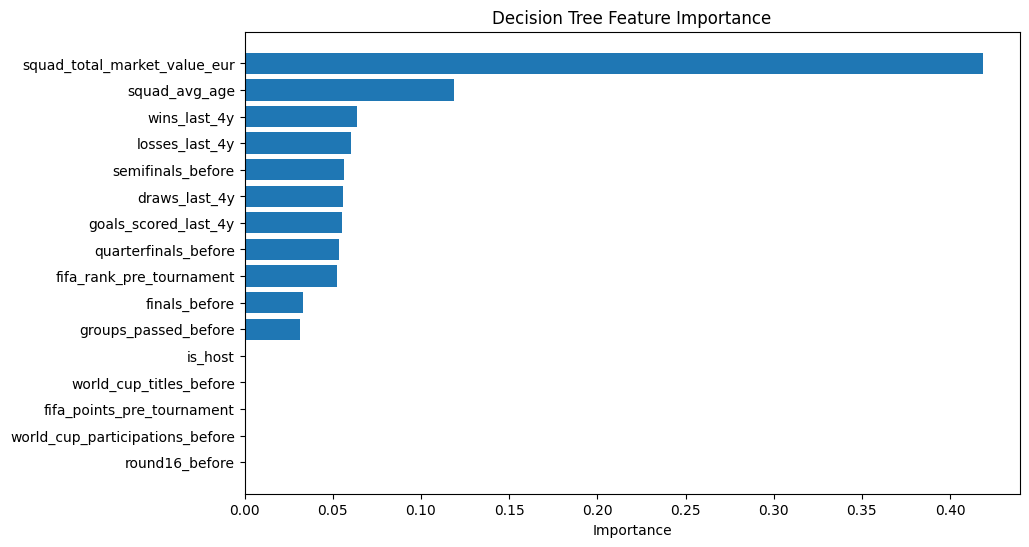

In [149]:
# @title
display(importance)
plt.figure(figsize=(10, 6))
plt.barh(importance["Feature"], importance["Importance"])
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("Decision Tree Feature Importance")
plt.show()

Although the Support Vector Machine was selected as the final predictive model, the Decision Tree provides useful insights into the relative importance of predictor variables. Figure 6 shows that squad market value was the most influential predictor of quarterfinal qualification. Other important variables included squad average age, recent wins, FIFA ranking, and historical World Cup performance indicators. These findings suggest that both current team strength and historical tournament experience contribute to success at the World Cup. Having identified the factors most strongly associated with quarterfinal qualification, the analysis now shifts from prediction to exploration by examining the underlying structure of teams through unsupervised learning methods.

### 4.3 Unsupervised Learning Results

#### Figure 7. Principal Component Analysis



In [150]:
# @title
print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("Total Explained Variance:")
print(sum(pca.explained_variance_ratio_))

display(loadings.sort_values("PC1", ascending=False))

Explained Variance Ratio:
[0.464142   0.11852807]
Total Explained Variance:
0.5826700645000767


,PC1,PC2
groups_passed_before,0.351258,-0.101005
quarterfinals_before,0.350102,-0.160911
round16_before,0.337079,-0.013768
semifinals_before,0.331213,-0.205236
world_cup_participations_before,0.329888,-0.037965
finals_before,0.320320,-0.221724
world_cup_titles_before,0.315268,-0.224766
squad_total_market_value_eur,0.273486,0.098050
fifa_points_pre_tournament,0.174546,0.322362
goals_scored_last_4y,0.147584,0.520676


In addition to supervised learning, unsupervised learning techniques were applied to explore similarities among teams and identify broader patterns within the data.

Principal Component Analysis (PCA) was applied to reduce the dimensionality of the dataset and identify the dominant sources of variation among teams. The first two principal components explain approximately 58.3% of the total variance, indicating that a substantial proportion of the information contained in the original sixteen predictor variables can be summarized using only two dimensions. PCA is commonly used to reduce complexity while preserving the major patterns present in the data.  

Examination of the loading values reveals that the first principal component (PC1) is primarily associated with historical World Cup success. Variables such as previous group-stage qualifications, quarterfinal appearances, semifinal appearances, finals appearances, World Cup titles, and tournament participations all exhibit strong positive loadings on this dimension. Consequently, PC1 can be interpreted as a measure of long-term World Cup strength and tournament experience.

The second principal component (PC2) is more strongly associated with recent team performance. Goals scored, wins during the previous four years, and FIFA points contribute most heavily to this component. Therefore, PC2 can be interpreted as a measure of current competitive form entering the tournament.

Together, these results suggest that World Cup teams can be characterized along two primary dimensions: historical tournament success and recent competitive performance. These two dimensions provide a natural framework for grouping teams with similar characteristics, motivating the clustering analysis presented in Figure 8.

#### Figure 8 and Table 6. K-Means Team Clustering

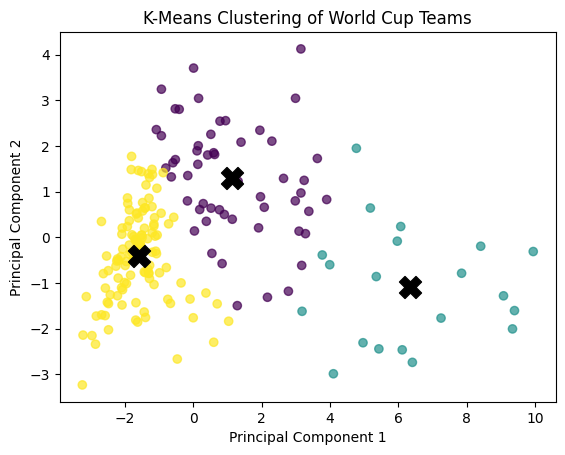

In [184]:
# @title
centers = kmeans.cluster_centers_

plt.scatter(pc[:,0], pc[:,1], c=clusters, alpha=0.7)

plt.scatter(
    centers[:,0],
    centers[:,1],
    marker='X',
    s=250,
    color='black'
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering of World Cup Teams")

plt.show()


Using the first two principal components as inputs, K-Means clustering was applied to identify groups of teams with similar competitive profiles. The clustering algorithm identified three distinct groups of World Cup teams. The clusters are reasonably well separated in the reduced two-dimensional space, suggesting that meaningful differences exist among teams in terms of historical success, squad quality, and recent performance.

Examination of the cluster summary statistics reveals clear differences between the three groups. Cluster 1 represents the elite football nations, characterized by the highest market values, strongest FIFA rankings, extensive World Cup experience, and the greatest number of historical titles and knockout-stage appearances. These teams have consistently performed at the highest level across multiple tournaments.

Cluster 0 represents strong and competitive teams that possess good recent performance and relatively high squad quality but have achieved less historical success than the elite group. These teams frequently advance beyond the group stage and occasionally reach the later knockout rounds, but they generally lack the sustained World Cup dominance observed in Cluster 1.

Cluster 2 contains emerging or lower-performing teams. Compared with the other clusters, these teams have lower market values, weaker FIFA rankings, fewer World Cup appearances, and substantially less historical tournament success. Their recent performance indicators are also lower on average.

Overall, the clustering results reinforce the findings from the PCA analysis. Teams can be broadly distinguished by two underlying dimensions: historical tournament success and current competitive strength. The existence of these distinct groups suggests that World Cup participants do not form a homogeneous population but instead belong to different competitive tiers. Having explored both the predictive and structural characteristics of the data, the final section applies the selected SVM model to generate predictions for the 2026 FIFA World Cup.

### 4.4 Prediction of the 2026 FIFA World Cup

#### Table 7. Predicted Quarterfinal Probabilities for 2026

In [152]:
# @title
display(predictions_2026.head(20))

,team,quarterfinal_probability,quarterfinal_prediction_threshold_020
1,Spain,0.613644,1
5,Brazil,0.598227,1
0,France,0.575242,1
3,England,0.571929,1
4,Portugal,0.551968,1
9,Germany,0.543479,1
6,Netherlands,0.529581,1
2,Argentina,0.336357,1
19,Turkey,0.285018,1
27,Norway,0.281625,1


Table 7 presents the quarterfinal qualification probabilities generated by the tuned SVM model for the 2026 FIFA World Cup. Spain, Brazil, France, England, Portugal, Germany, and the Netherlands received the highest predicted probabilities, all exceeding 50%. Argentina was also predicted to reach the quarterfinal stage despite receiving a substantially lower probability than the leading European nations. Several additional teams, including Turkey, Norway, Sweden, Belgium, and Morocco, were identified as potential contenders, although with considerably lower predicted probabilities.

#### Table 8. Comparison with Elo Ratings

In [174]:
# @title
display(comparison_table)

,Team,SVM Probability (%),Elo Rank
0,Spain,61.4,1.0
1,Brazil,59.8,5.0
2,France,57.5,3.0
3,England,57.2,4.0
4,Portugal,55.2,5.0
5,Germany,54.3,11.0
6,Netherlands,53.0,8.0
7,Argentina,33.6,2.0
8,Turkey,28.5,14.0
9,Norway,28.2,12.0


To further evaluate the plausibility of these predictions, the model results were compared with contemporary Elo ratings, a widely used benchmark of international football strength.

Table 8 compares the top teams identified by the SVM model with their corresponding Elo rankings. The two approaches show substantial agreement, with Spain, France, England, Brazil, Portugal, and the Netherlands appearing among the strongest teams according to both methods. This consistency suggests that the model successfully captures many of the factors associated with established football strength.

Notable differences also emerge. Argentina, despite being ranked second in the Elo system, received a lower quarterfinal probability from the SVM model. This discrepancy indicates that the machine learning model incorporates additional information beyond Elo ratings, including historical World Cup performance, squad characteristics, and recent competitive results. Overall, the comparison provides additional confidence that the model’s predictions are broadly consistent with an independent football rating system while still offering unique insights.

The prediction results indicate that several traditionally strong football nations, including Spain, France, England, Brazil, Portugal, Germany, and the Netherlands, remain among the most likely candidates to reach the quarterfinal stage of the 2026 FIFA World Cup. Furthermore, the substantial agreement between the SVM predictions and Elo rankings provides additional confidence in the model’s ability to identify competitive teams. Having examined the data through exploratory analysis, supervised learning, unsupervised learning, and future tournament prediction, the final section summarizes the key findings and discusses potential directions for future research.

## Conclusion and Future Study

This project applied both supervised and unsupervised learning techniques to historical FIFA World Cup data to investigate the factors associated with quarterfinal qualification and to generate predictions for the 2026 FIFA World Cup. Using information on recent performance, FIFA rankings, squad characteristics, market value, and historical tournament experience, the analysis explored how different dimensions of team strength contribute to success in international football.

The exploratory analysis revealed that stronger FIFA rankings, higher squad market values, and greater historical World Cup experience were generally associated with a higher likelihood of reaching the quarterfinal stage. Among the supervised learning methods considered, the tuned Support Vector Machine achieved the strongest overall predictive performance and was selected as the final model. After threshold optimization, the model achieved a balanced trade-off between accuracy and recall, allowing it to identify a majority of quarterfinalist teams while maintaining strong overall classification performance. The unsupervised learning analysis further showed that teams can largely be characterized along two underlying dimensions: historical tournament success and recent competitive form. These dimensions also produced meaningful clusters corresponding to elite football nations, strong competitors, and emerging teams.

Applying the final model to the 2026 FIFA World Cup identified Spain, Brazil, France, England, Portugal, Germany, and the Netherlands as the strongest candidates to reach the quarterfinal stage. Comparison with contemporary Elo rankings showed substantial agreement between the machine learning predictions and an established football rating system, providing additional support for the plausibility of the results. Although tournament outcomes remain inherently uncertain, the findings suggest that both historical success and current competitive strength continue to play important roles in determining World Cup performance.

Several limitations should be acknowledged. First, the historical dataset contains only 192 observations, which limits the amount of information available for model training and evaluation. Second, the analysis relied primarily on team-level variables and did not incorporate potentially important factors such as player injuries, coaching decisions, tactical approaches, betting market expectations, or match-level statistics. In addition, some variables may not fully capture the impact of exceptional individual players. For example, squad market value is influenced by age and future transfer potential, which may undervalue experienced world-class players who continue to perform at an elite level. Lionel Messi provides a useful example, as his market value has declined substantially with age despite remaining one of the most influential players in international football. Therefore, market value may not always reflect the true competitive strength of teams containing elite veteran players.   Finally, relationships observed in previous tournaments may not fully reflect future tournament dynamics.

Future research could incorporate player-level information, advanced match statistics, and additional performance metrics such as Elo ratings directly as predictive features. Future models could also account for the influence of exceptional individual players whose competitive impact may not be fully reflected in team-level variables such as squad market value. For example, experienced world-class players may continue to perform at an elite level despite age-related declines in market valuation. Other machine learning methods, including Random Forests, Gradient Boosting, and ensemble approaches, could also be evaluated and compared. These extensions may improve predictive performance while providing a deeper understanding of the factors that contribute to success in the FIFA World Cup.


# References

1. Harrachi, M. FIFA World Cup Dataset. Kaggle. Available at: https://www.kaggle.com/datasets/harrachimustapha/fifa-world-cup-team-dataset. Accessed June 2026.

2. Cruz, A. F. 2026 FIFA World Cup — Historical Elo Ratings. Kaggle. Available at: https://www.kaggle.com/datasets/afonsofernandescruz/2026-fifa-world-cup-historical-elo-ratings. Accessed June 2026.

3. World Football Elo Ratings. Available at: https://www.eloratings.net/. Accessed June 2026.

4. Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine Learning in Python. Journal of Machine Learning Research, 12, 2825–2830.

# Appendix

The appendix contains the Python code used for data preprocessing, exploratory data analysis, supervised learning, unsupervised learning, model evaluation, threshold optimization, and 2026 FIFA World Cup prediction.

Major analytical procedures include:

- Data cleaning and median imputation
- Exploratory data analysis and visualization
- Decision Tree classification
- Support Vector Machine classification
- Hyperparameter tuning using Randomized Search and cross-validation
- Threshold optimization
- Principal Component Analysis (PCA)
- K-Means clustering
- 2026 FIFA World Cup quarterfinal prediction
- Elo rating comparison

Mathematical Formulas

Support Vector Machine:
f(x)=sign(w^Tx+b)

Principal Component Analysis:
PC=XW

K-Means Clustering:
min Σ||x−μ||²

<div style="page-break-before: always;"></div>

In [192]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [193]:
!jupyter nbconvert \
--to html \
--no-input \
--output FIFA_World_Cup_2026_Report.html \
"/content/drive/MyDrive/Colab Notebooks/FIFA_World_Cup_2026_Project.ipynb"

[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/FIFA_World_Cup_2026_Project.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 6 image(s).
[NbConvertApp] Writing 715319 bytes to /content/drive/MyDrive/Colab Notebooks/FIFA_World_Cup_2026_Report.html


In [194]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/Colab Notebooks/FIFA_World_Cup_2026_Report.html"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>